# 02 - Modeling
Pipeline akhir: `BuildingFeatureEngineer` -> `ColumnTransformer` -> `LGBMClassifier` (tanpa Neural Network).

Alur: baca data -> split -> preprocessing -> baseline & strategi multi-kelas (OvR/OvO) -> training -> hyperparameter tuning -> evaluasi -> bobot kelas untuk Macro F1 -> feature importance -> simpan model.

In [1]:
import sys, warnings, json, time, joblib
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn import set_config
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

from scripts.preprocess import (load_data, encode_target, build_preprocessor,
                                CATEGORICAL_COLS, GEO_CAT_COLS)
from scripts.feature_engineering import BuildingFeatureEngineer
from scripts.train import build_pipeline, macro_f1, tune_class_weights, DEFAULT_PARAMS

sns.set_theme(style="whitegrid")
set_config(display="diagram")
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
NAMES = ["Grade 1", "Grade 2", "Grade 3", "Grade 4", "Grade 5"]

# **1. Read Data**

In [2]:
train, test, sample = load_data()
X = train.drop(columns=["damage_grade"])
y = pd.Series(encode_target(train["damage_grade"]), index=train.index, name="damage_grade")  # 0..4
print(X.shape, test.shape)
y.value_counts(normalize=True).sort_index().round(3)

(533465, 16) (228629, 16)


damage_grade
0    0.103
1    0.114
2    0.179
3    0.241
4    0.362
Name: proportion, dtype: float64

# **2. Dataset Splitting**
Holdout 80/20 dengan `stratify=y` supaya proporsi kelas sama di kedua bagian (target imbalance). Holdout ini dipakai untuk membandingkan model dan hasil tuning; hasil CV 5-fold pada seluruh train ada di bagian 7.

In [3]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("X_train:", X_train.shape, "| X_valid:", X_valid.shape)
pd.concat([y_train.value_counts(normalize=True).sort_index(),
           y_valid.value_counts(normalize=True).sort_index()], axis=1, keys=["train", "valid"]).round(3)

X_train: (426772, 16) | X_valid: (106693, 16)


,train,valid
damage_grade,,
0,0.103,0.103
1,0.114,0.114
2,0.179,0.179
3,0.241,0.241
4,0.362,0.362


# **3. Preprocessing**
Tiga tahap, semuanya di dalam satu `Pipeline` supaya tidak ada kebocoran data saat cross-validation:
1. `BuildingFeatureEngineer`: fitur turunan (rasio bentuk bangunan, umur di-clip + flag, kode lokasi dari `building_id`).
2. `CategoryCaster` (di `ColumnTransformer`): kolom kategorik dan kode lokasi jadi dtype `category` untuk penanganan native LightGBM.
3. Kolom numerik diteruskan (`passthrough`); model pohon tidak butuh scaling.

In [4]:
fe = BuildingFeatureEngineer()
demo = fe.fit_transform(X_train.head(5))
print("kolom awal :", X_train.shape[1], "| setelah feature engineering:", demo.shape[1])
display(demo[["count_floors_pre_eq", "plinth_area_sq_ft", "height_ft_pre_eq", "age_building",
              "area_per_floor", "height_per_floor", "slenderness", "volume_proxy",
              "age_unknown", "age_clipped", "b_vdc", "b_ward", "b_seq"]])

kolom awal : 16 | setelah feature engineering: 24


,count_floors_pre_eq,plinth_area_sq_ft,height_ft_pre_eq,age_building,area_per_floor,height_per_floor,slenderness,volume_proxy,age_unknown,age_clipped,b_vdc,b_ward,b_seq
265990,2,340,18,27,170.0,9.0,0.976187,6120,0,27,2221,222102,751
140707,2,428,16,20,214.0,8.0,0.773389,6848,0,20,2905,290502,20051
241061,2,268,12,8,134.0,6.0,0.733017,3216,0,8,3044,304405,101
89995,1,515,6,45,515.0,6.0,0.264392,3090,0,45,2913,291301,362
475729,2,299,21,17,149.5,10.5,1.214461,6279,0,17,3139,313907,331


In [5]:
prep = build_preprocessor(fe.numeric_columns())
prep

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The

In [6]:
pre = Pipeline([("features", BuildingFeatureEngineer()), ("prep", build_preprocessor(fe.numeric_columns()))])
Xt = pre.fit_transform(X_train.sample(20000, random_state=0))
print("bentuk hasil preprocessing:", Xt.shape)
print(Xt.dtypes.astype(str).value_counts().to_dict())
print("kolom kategori:", list(Xt.select_dtypes("category").columns))
print("kolom numerik :", list(Xt.select_dtypes("number").columns))

bentuk hasil preprocessing: (20000, 24)
{'category': 12, 'int64': 9, 'float64': 3}
kolom kategori: ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'superstructure', 'vdcmun_id', 'ward_id', 'b_vdc', 'b_ward']
kolom numerik : ['district_id', 'count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'area_per_floor', 'height_per_floor', 'slenderness', 'volume_proxy', 'age_unknown', 'age_clipped', 'b_seq']


# **4. Baseline dan strategi multi-kelas**
Sebelum model utama, dibandingkan dulu beberapa baseline pada **subset 60.000 baris** (hemat waktu), dievaluasi pada 20.000 baris holdout:
- `DummyClassifier`: batas bawah.
- `LogisticRegression` dengan **One-vs-Rest** dan **One-vs-One** (materi multi-kelas). Pipeline linear memakai `SimpleImputer` + `StandardScaler` untuk numerik dan `SimpleImputer` + `OneHotEncoder` untuk kategorik.
- `RandomForest` sebagai pembanding berbasis pohon.
- `LightGBM` (native multiclass softmax).

In [7]:
def linear_preprocessor():
    fe_ = BuildingFeatureEngineer()
    num_cols = [c for c in fe_.numeric_columns() if c not in GEO_CAT_COLS]
    cat_cols = CATEGORICAL_COLS + ["vdcmun_id", "b_vdc"]   # kode lokasi halus (ward) dilewati agar OHE tidak terlalu lebar
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=20))])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])

def make_baseline(algo):
    return Pipeline([("features", BuildingFeatureEngineer()), ("prep", linear_preprocessor()), ("algo", algo)])

Xs, _, ys, _ = train_test_split(X_train, y_train, train_size=60000, stratify=y_train, random_state=0)
Xv, _, yv, _ = train_test_split(X_valid, y_valid, train_size=20000, stratify=y_valid, random_state=0)

candidates = {
    "Dummy (most frequent)": make_baseline(DummyClassifier(strategy="most_frequent")),
    "LogReg + OvR": make_baseline(OneVsRestClassifier(LogisticRegression(max_iter=300))),
    "LogReg + OvO": make_baseline(OneVsOneClassifier(LogisticRegression(max_iter=300))),
    "RandomForest": make_baseline(RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=2, random_state=42)),
    "LightGBM (pipeline akhir)": build_pipeline({"n_estimators": 200}),
}
rows = []
for name, model in candidates.items():
    t0 = time.time()
    model.fit(Xs, ys)
    pred = model.predict(Xv)
    rows.append({"model": name, "accuracy": accuracy_score(yv, pred),
                 "macro_f1": f1_score(yv, pred, average="macro"), "detik": time.time() - t0})
    print(rows[-1], flush=True)
baseline = pd.DataFrame(rows).round(4)
baseline

{'model': 'Dummy (most frequent)', 'accuracy': 0.36185, 'macro_f1': 0.10628189595036164, 'detik': 0.7308187484741211}


{'model': 'LogReg + OvR', 'accuracy': 0.54005, 'macro_f1': 0.47549707029898836, 'detik': 4.570625305175781}


{'model': 'LogReg + OvO', 'accuracy': 0.5405, 'macro_f1': 0.4800372608486156, 'detik': 3.9364240169525146}


{'model': 'RandomForest', 'accuracy': 0.54625, 'macro_f1': 0.47564264831893155, 'detik': 27.479424238204956}


{'model': 'LightGBM (pipeline akhir)', 'accuracy': 0.57265, 'macro_f1': 0.5321481257462649, 'detik': 13.633420467376709}


,model,accuracy,macro_f1,detik
0,Dummy (most frequent),0.3618,0.1063,0.7308
1,LogReg + OvR,0.5400,0.4755,4.5706
2,LogReg + OvO,0.5405,0.4800,3.9364
3,RandomForest,0.5462,0.4756,27.4794
4,LightGBM (pipeline akhir),0.5726,0.5321,13.6334


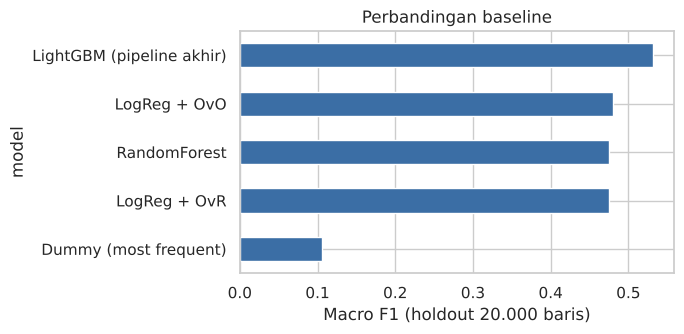

In [8]:
ax = baseline.set_index("model")["macro_f1"].sort_values().plot.barh(color="#3b6ea5", figsize=(7, 3.5))
ax.set_xlabel("Macro F1 (holdout 20.000 baris)"); ax.set_title("Perbandingan baseline")
plt.tight_layout(); plt.savefig(FIG / "baseline_comparison.png", dpi=130); plt.show()

**Pembacaan hasil:**
- Dummy hanya menebak kelas mayoritas, jadi Macro F1-nya sangat rendah.
- OvO sedikit lebih baik dari OvR pada Logistic Regression, tapi selisihnya kecil.
- RandomForest di setup ini tidak lebih baik dari model linear, dan lebih lambat.
- LightGBM paling tinggi. Catatan jujur: sebagian keunggulannya datang dari fitur lokasi halus (`ward_id`, `b_ward`) yang diolah sebagai kategori native. Baseline di atas tidak memakai kode lokasi sehalus itu (one-hot-nya akan terlalu lebar), jadi perbandingannya bukan murni "algoritma vs algoritma".

Pipeline LightGBM dipakai sebagai model utama.

# **5. Training model utama**
Pipeline lengkap dengan parameter default (600 pohon) dilatih pada **seluruh `X_train`** (80% data).

In [9]:
pipeline = build_pipeline()
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,age_cap,200
,use_building_id,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fea

In [10]:
t0 = time.time()
pipeline.fit(X_train, y_train)
print(f"selesai dalam {time.time() - t0:.0f} detik")
proba_default = pipeline.predict_proba(X_valid)
y_pred = proba_default.argmax(1)
print("Macro F1 holdout (default):", round(f1_score(y_valid, y_pred, average="macro"), 4))
print("Accuracy                  :", round(accuracy_score(y_valid, y_pred), 4))

selesai dalam 176 detik


Macro F1 holdout (default): 0.5793
Accuracy                  : 0.6147


In [11]:
print(classification_report(y_valid, y_pred, target_names=NAMES, digits=3))

              precision    recall  f1-score   support

     Grade 1      0.661     0.738     0.697     11034
     Grade 2      0.456     0.404     0.429     12216
     Grade 3      0.476     0.450     0.463     19098
     Grade 4      0.556     0.543     0.549     25738
     Grade 5      0.742     0.775     0.758     38607

    accuracy                          0.615    106693
   macro avg      0.578     0.582     0.579    106693
weighted avg      0.608     0.615     0.611    106693



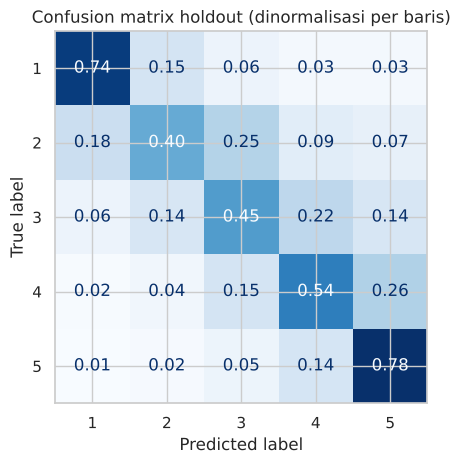

In [12]:
ConfusionMatrixDisplay.from_predictions(y_valid + 1, y_pred + 1, cmap="Blues", colorbar=False, normalize="true",
                                        values_format=".2f")
plt.title("Confusion matrix holdout (dinormalisasi per baris)")
plt.tight_layout(); plt.show()

# **6. Hyperparameter Tuning**
`pipeline.get_params()` menunjukkan parameter yang bisa dituning; parameter model diawali `model__`.
Dipakai `RandomizedSearchCV` (3-fold stratified, `scoring="f1_macro"`) pada **subset 60.000 baris** agar cepat. Jumlah pohon dibuat tetap 200 selama pencarian, lalu parameter terbaik dilatih ulang pada seluruh `X_train` dengan 600 pohon.

In [13]:
[k for k in build_pipeline().get_params().keys() if k.startswith("model__")][:12]

['model__boosting_type',
 'model__class_weight',
 'model__colsample_bytree',
 'model__importance_type',
 'model__learning_rate',
 'model__max_depth',
 'model__min_child_samples',
 'model__min_child_weight',
 'model__min_split_gain',
 'model__n_estimators',
 'model__n_jobs',
 'model__num_leaves']

In [14]:
param_dist = {
    "model__num_leaves": [31, 63, 127, 255],
    "model__learning_rate": [0.05, 0.1],
    "model__min_child_samples": [10, 30, 60, 100],
    "model__colsample_bytree": [0.5, 0.7, 0.9],
    "model__reg_lambda": [0, 1, 5, 10],
}
Xtune, _, ytune, _ = train_test_split(X_train, y_train, train_size=60000, stratify=y_train, random_state=1)

search = RandomizedSearchCV(
    build_pipeline({"n_estimators": 200}), param_dist, n_iter=6,
    cv=StratifiedKFold(3, shuffle=True, random_state=42), scoring="f1_macro",
    n_jobs=1, random_state=42, verbose=2, refit=False,
)
t0 = time.time()
search.fit(Xtune, ytune)
print(f"tuning selesai dalam {time.time() - t0:.0f} detik")
print("Best params:", search.best_params_)
print("Best CV Macro F1 (subset):", round(search.best_score_, 4))

Fitting 3 folds for each of 6 candidates, totalling 18 fits


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.05, model__min_child_samples=10, model__num_leaves=255, model__reg_lambda=0; total time=  15.6s


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.05, model__min_child_samples=10, model__num_leaves=255, model__reg_lambda=0; total time=  16.4s


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.05, model__min_child_samples=10, model__num_leaves=255, model__reg_lambda=0; total time=  14.3s


[CV] END model__colsample_bytree=0.7, model__learning_rate=0.1, model__min_child_samples=100, model__num_leaves=127, model__reg_lambda=5; total time=  11.1s


[CV] END model__colsample_bytree=0.7, model__learning_rate=0.1, model__min_child_samples=100, model__num_leaves=127, model__reg_lambda=5; total time=  11.2s


[CV] END model__colsample_bytree=0.7, model__learning_rate=0.1, model__min_child_samples=100, model__num_leaves=127, model__reg_lambda=5; total time=  10.2s


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.1, model__min_child_samples=60, model__num_leaves=31, model__reg_lambda=10; total time=   7.4s


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.1, model__min_child_samples=60, model__num_leaves=31, model__reg_lambda=10; total time=   7.2s


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.1, model__min_child_samples=60, model__num_leaves=31, model__reg_lambda=10; total time=   7.2s


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.1, model__min_child_samples=10, model__num_leaves=255, model__reg_lambda=0; total time=  15.5s


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.1, model__min_child_samples=10, model__num_leaves=255, model__reg_lambda=0; total time=  15.5s


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.1, model__min_child_samples=10, model__num_leaves=255, model__reg_lambda=0; total time=  14.8s


[CV] END model__colsample_bytree=0.5, model__learning_rate=0.05, model__min_child_samples=100, model__num_leaves=127, model__reg_lambda=0; total time=  11.2s


[CV] END model__colsample_bytree=0.5, model__learning_rate=0.05, model__min_child_samples=100, model__num_leaves=127, model__reg_lambda=0; total time=  11.7s


[CV] END model__colsample_bytree=0.5, model__learning_rate=0.05, model__min_child_samples=100, model__num_leaves=127, model__reg_lambda=0; total time=  11.1s


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.1, model__min_child_samples=100, model__num_leaves=63, model__reg_lambda=0; total time=   9.0s


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.1, model__min_child_samples=100, model__num_leaves=63, model__reg_lambda=0; total time=   9.3s


[CV] END model__colsample_bytree=0.9, model__learning_rate=0.1, model__min_child_samples=100, model__num_leaves=63, model__reg_lambda=0; total time=   9.7s
tuning selesai dalam 208 detik
Best params: {'model__reg_lambda': 10, 'model__num_leaves': 31, 'model__min_child_samples': 60, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.9}
Best CV Macro F1 (subset): 0.5202


In [15]:
res = pd.DataFrame(search.cv_results_)
cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score"]
res[cols].sort_values("rank_test_score").round(4)

,param_model__reg_lambda,param_model__num_leaves,param_model__min_child_samples,param_model__learning_rate,param_model__colsample_bytree,mean_test_score,std_test_score,rank_test_score
2,10,31,60,0.10,0.9,0.5202,0.0019,1
4,0,127,100,0.05,0.5,0.5173,0.0029,2
5,0,63,100,0.10,0.9,0.5158,0.0014,3
1,5,127,100,0.10,0.7,0.5128,0.0003,4
0,0,255,10,0.05,0.9,0.5124,0.0026,5
3,0,255,10,0.10,0.9,0.5058,0.0046,6


In [16]:
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
best_params["n_estimators"] = DEFAULT_PARAMS["n_estimators"]
print("parameter untuk model akhir:", best_params)
best_model = build_pipeline(best_params)
t0 = time.time()
best_model.fit(X_train, y_train)
print(f"selesai dalam {time.time() - t0:.0f} detik")
proba_tuned = best_model.predict_proba(X_valid)

parameter untuk model akhir: {'reg_lambda': 10, 'num_leaves': 31, 'min_child_samples': 60, 'learning_rate': 0.1, 'colsample_bytree': 0.9, 'n_estimators': 600}


selesai dalam 120 detik


# **7. Evaluation**

In [17]:
summary = pd.DataFrame({
    "model": ["LightGBM default", "LightGBM hasil tuning"],
    "accuracy": [accuracy_score(y_valid, proba_default.argmax(1)), accuracy_score(y_valid, proba_tuned.argmax(1))],
    "macro_f1": [macro_f1(y_valid.values, proba_default), macro_f1(y_valid.values, proba_tuned)],
}).round(4)
summary

,model,accuracy,macro_f1
0,LightGBM default,0.6147,0.5793
1,LightGBM hasil tuning,0.6108,0.5761


Pada holdout, model hasil tuning **tidak mengalahkan** parameter default. Pencarian dilakukan pada subset 60.000 baris, sehingga memilih pohon yang kecil (`num_leaves` rendah) yang cocok untuk data kecil tapi kurang cocok untuk data penuh (426 ribu baris). Karena itu **parameter default dipertahankan** sebagai model final.

In [18]:
print("== Hasil tuning ==")
print(classification_report(y_valid, proba_tuned.argmax(1), target_names=NAMES, digits=3))

== Hasil tuning ==
              precision    recall  f1-score   support

     Grade 1      0.658     0.749     0.701     11034
     Grade 2      0.457     0.401     0.427     12216
     Grade 3      0.471     0.441     0.455     19098
     Grade 4      0.552     0.538     0.545     25738
     Grade 5      0.736     0.770     0.753     38607

    accuracy                          0.611    106693
   macro avg      0.575     0.580     0.576    106693
weighted avg      0.604     0.611     0.607    106693



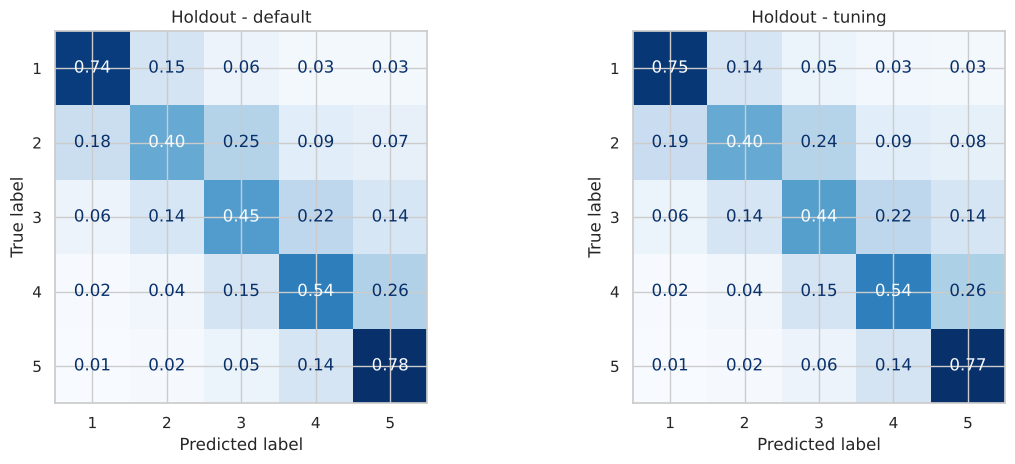

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (title, pr) in zip(axes, [("default", proba_default), ("tuning", proba_tuned)]):
    ConfusionMatrixDisplay.from_predictions(y_valid + 1, pr.argmax(1) + 1, cmap="Blues", colorbar=False,
                                            normalize="true", values_format=".2f", ax=ax)
    ax.set_title(f"Holdout - {title}")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix_holdout.png", dpi=120); plt.show()

### Optimasi bobot kelas untuk Macro F1
Probabilitas tiap kelas dikalikan bobot sebelum `argmax`. Bobot dicari dengan coordinate ascent pada probabilitas **out-of-fold** (5-fold CV pada seluruh train, dibuat oleh `python -m scripts.train`) agar tidak mengintip label holdout.

In [20]:
oof = np.load(ROOT / "models" / "oof_proba.npy")
meta = json.load(open(ROOT / "models" / "class_weights.json"))
w = np.array(meta["class_weights"])
y_all = y.values
print("CV 5-fold Macro F1 (argmax)       :", round(macro_f1(y_all, oof), 4))
print("CV 5-fold Macro F1 (+ bobot kelas):", round(macro_f1(y_all, oof, w), 4), "| w =", np.round(w, 3))
print("Holdout, model default + bobot    :", round(macro_f1(y_valid.values, proba_default, w), 4))
print("Holdout, model tuning  + bobot    :", round(macro_f1(y_valid.values, proba_tuned, w), 4))

CV 5-fold Macro F1 (argmax)       : 0.5824
CV 5-fold Macro F1 (+ bobot kelas): 0.5871 | w = [1.    1.286 1.183 1.088 0.777]
Holdout, model default + bobot    : 0.5839
Holdout, model tuning  + bobot    : 0.5812


              precision    recall  f1-score   support

           1      0.685     0.696     0.691     55170
           2      0.442     0.469     0.455     61080
           3      0.464     0.484     0.474     95488
           4      0.543     0.589     0.565    128691
           5      0.794     0.712     0.751    193036

    accuracy                          0.612    533465
   macro avg      0.585     0.590     0.587    533465
weighted avg      0.623     0.612     0.616    533465



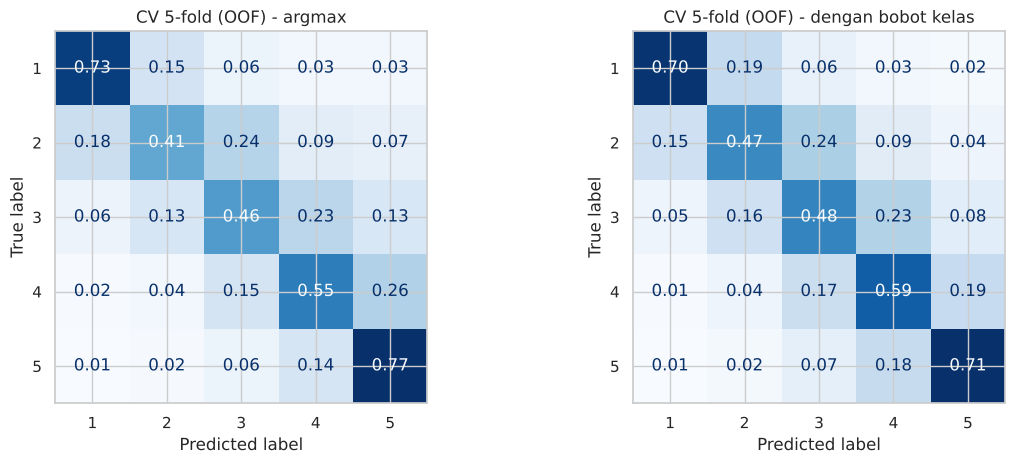

In [21]:
print(classification_report(y_all + 1, (oof * w).argmax(1) + 1, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (title, pred) in zip(axes, [("argmax", oof.argmax(1)), ("dengan bobot kelas", (oof * w).argmax(1))]):
    ConfusionMatrixDisplay.from_predictions(y_all + 1, pred + 1, cmap="Blues", colorbar=False,
                                            normalize="true", values_format=".2f", ax=ax)
    ax.set_title(f"CV 5-fold (OOF) - {title}")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=120); plt.show()

# **8. Feature importance**
Dihitung dari model final (`models/pipeline_model_lgbm.pkl`, parameter default, dilatih pada seluruh train).

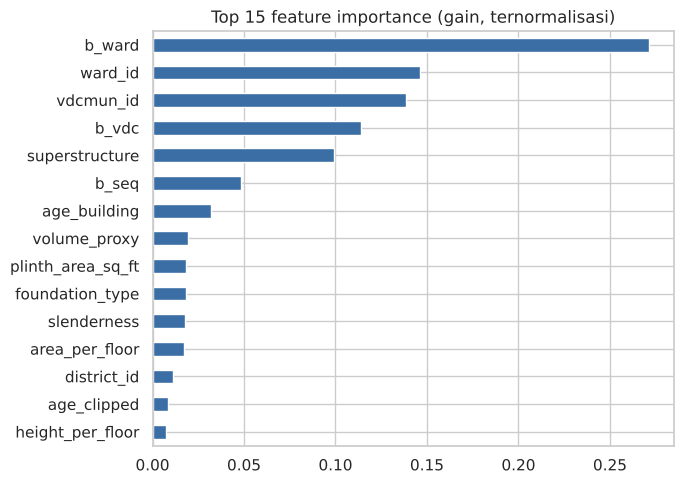

b_ward               0.271
ward_id              0.146
vdcmun_id            0.139
b_vdc                0.114
superstructure       0.099
b_seq                0.048
age_building         0.032
volume_proxy         0.019
plinth_area_sq_ft    0.018
foundation_type      0.018
dtype: float64

In [22]:
final_model = joblib.load(ROOT / "models" / "pipeline_model_lgbm.pkl")
names = final_model[:-1].transform(X_valid.head(2)).columns
imp = pd.Series(final_model[-1].booster_.feature_importance("gain"), index=names).sort_values()
imp = imp / imp.sum()
ax = imp.tail(15).plot.barh(figsize=(7, 5), color="#3b6ea5")
ax.set_title("Top 15 feature importance (gain, ternormalisasi)")
plt.tight_layout(); plt.savefig(FIG / "feature_importance.png", dpi=130); plt.show()
imp.sort_values(ascending=False).head(10).round(3)

# **9. Save Model**
Model dengan Macro F1 holdout terbaik (default vs tuning) disimpan untuk referensi. **Model untuk submission** dilatih pada seluruh train lewat `python -m scripts.train` (file `models/pipeline_model_lgbm.pkl`) dan dipakai oleh `scripts/predict.py`.

In [23]:
f_def = macro_f1(y_valid.values, proba_default)
f_tun = macro_f1(y_valid.values, proba_tuned)
chosen_name, chosen = ("default", pipeline) if f_def >= f_tun else ("tuning", best_model)
path = ROOT / "models" / "pipeline_model_lgbm_holdout.pkl"
joblib.dump(chosen, path)
print(f"model terbaik di holdout: {chosen_name} (default={f_def:.4f}, tuning={f_tun:.4f})")
print("tersimpan:", path)
print("params tuning yang dicoba:", best_params)

model terbaik di holdout: default (default=0.5793, tuning=0.5761)
tersimpan: /home/claude/structural-damage-classification/models/pipeline_model_lgbm_holdout.pkl
params tuning yang dicoba: {'reg_lambda': 10, 'num_leaves': 31, 'min_child_samples': 60, 'learning_rate': 0.1, 'colsample_bytree': 0.9, 'n_estimators': 600}
